In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

In [2]:
termo_norm = {}
termo = {}
    
file_termo_norm = f"../../../output/termonorm_FS.dat"
df = pd.read_csv(file_termo_norm, delim_whitespace=True)

termo_norm = {
    "df": df,
    "theta": df.iloc[:,0]*180./np.pi,
}

file_termo = f"../../../output/termo_FS.dat"
df = pd.read_csv(file_termo, delim_whitespace=True)

termo = {
    "df": df,
    "rho_HL": df.iloc[:,1],
    "rho_IL": df.iloc[:,-1],
    "rho_ISM": df.iloc[:,-2],
    "T": df.iloc[:,4]
}

In [3]:
T_ISM = 8e3

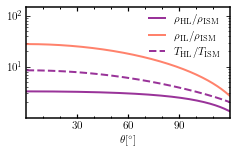

In [45]:
fig, ax = plt.subplots(figsize=(0.6*text_width, 2./3.*0.5*text_width))

ax.set_yscale('log')

ax.plot(termo_norm["theta"],
        termo["rho_HL"]/termo['rho_ISM'],
        color='purple', lw=2, alpha=0.8,
        label=r"$\rho_{\rm HL}/\rho_{\rm ISM}$")

ax.plot(termo_norm["theta"],
        termo["rho_IL"]/termo['rho_ISM'],
        color='tomato', lw=2, alpha=0.8,
        label=r"$\rho_{\rm IL}/\rho_{\rm ISM}$")

ax.plot(termo_norm["theta"],
        termo["T"]/T_ISM,
        color='purple', lw=2, ls='--', alpha=0.8,
        label=r"$T_{\rm HL}/T_{\rm ISM}$")

ax.set_xlim(0,120.)
ax.set_xticks([30., 60., 90.])
ax.set_xticks([10, 20, 40, 50, 70, 80,
                  100, 110], minor = True)

ax.set_ylim(1,150)
ax.set_yticks([10, 100])
ax.set_yticks([2, 3, 4, 5, 6, 7, 8, 9,
               20, 30, 40, 50, 60, 70, 80, 90], minor = True)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

ax.set_xlabel(r"$\theta [^\circ]$")

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper right",
    bbox_to_anchor=(0.9, 0.9),
    ncol=1,
    frameon=False,
    handlelength=1.5
)
    
plt.show()

In [46]:
#fig.savefig('termo_FS_runaways.pdf', bbox_inches='tight', pad_inches = 0.02)